# LAB3 - Phần 2 - Bài 5

Gom cụm bộ dữ liệu MNIST bằng thuật toán k-Means, sau đó so sánh kết quả gom cụm với nhãn lớp có sẵn.

## 1. Đọc dữ liệu

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'   # tránh cảnh báo memory leak của KMeans trên Windows

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.cluster import KMeans
from sklearn import metrics
from keras.datasets import mnist

In [2]:
# Đọc bộ dữ liệu train, test của MNIST từ Keras
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

print("Train images:", train_images.shape, "- Train labels:", train_labels.shape)
print("Test images:", test_images.shape, "- Test labels:", test_labels.shape)

Train images: (60000, 28, 28) - Train labels: (60000,)
Test images: (10000, 28, 28) - Test labels: (10000,)


Đặng Phan Duy - 6451071010

          0     1     2     3     4     5     6     7     8     9
count  5923  6742  5958  6131  5842  5421  5918  6265  5851  5949


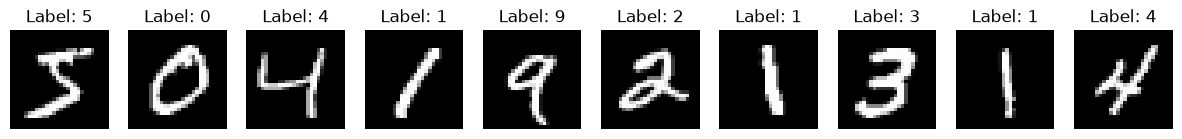

In [3]:
# Số lượng ảnh của từng chữ số trong tập train
print(pd.Series(train_labels).value_counts().sort_index().to_frame('count').T)

# Hiển thị một số ảnh mẫu
plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(train_images[i], cmap='gray')
    plt.title('Label: {0}'.format(train_labels[i]))
    plt.axis('off')
plt.show()

Đặng Phan Duy - 6451071010

## 2. Tiền xử lý dữ liệu

In [4]:
# Chuẩn hóa giá trị pixel về đoạn [0,1] và làm phẳng ảnh 28x28 thành vector 784 chiều
X_train = train_images.reshape(len(train_images), -1) / 255.0
X_test = test_images.reshape(len(test_images), -1) / 255.0

print("X_train:", X_train.shape, "- Min:", X_train.min(), "- Max:", X_train.max())
print("X_test:", X_test.shape, "- Min:", X_test.min(), "- Max:", X_test.max())

X_train: (60000, 784) - Min: 0.0 - Max: 1.0
X_test: (10000, 784) - Min: 0.0 - Max: 1.0


Đặng Phan Duy - 6451071010

## 3. Gom cụm bằng k-Means

MNIST có 10 chữ số (0 - 9) nên chọn số cụm k = 10. Huấn luyện k-Means trên tập train (không sử dụng nhãn).

In [5]:
kmeans = KMeans(n_clusters=10, n_init=10, random_state=42)
kmeans.fit(X_train)

train_clusters = kmeans.labels_
print("Inertia:", kmeans.inertia_)
print("Số lượng mẫu trong từng cụm:")
print(pd.Series(train_clusters).value_counts().sort_index().to_frame('count').T)

Inertia: 2352826.6299970257
Số lượng mẫu trong từng cụm:
          0     1     2     3     4     5     6     7     8     9
count  5720  5966  6526  4679  3178  5592  8855  8934  7454  3096


Đặng Phan Duy - 6451071010

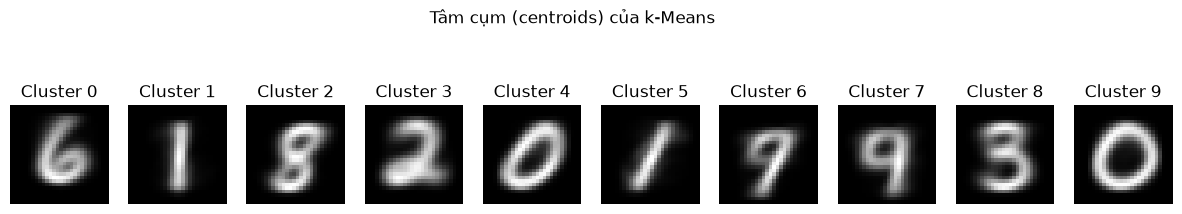

In [6]:
# Hiển thị tâm của 10 cụm dưới dạng ảnh 28x28
plt.figure(figsize=(15, 3))
for i, center in enumerate(kmeans.cluster_centers_):
    plt.subplot(1, 10, i + 1)
    plt.imshow(center.reshape(28, 28), cmap='gray')
    plt.title('Cluster {0}'.format(i))
    plt.axis('off')
plt.suptitle('Tâm cụm (centroids) của k-Means')
plt.show()

Đặng Phan Duy - 6451071010

## 4. So sánh cụm với nhãn lớp có sẵn

### 4.1. Bảng phân bố nhãn thực tế trong từng cụm

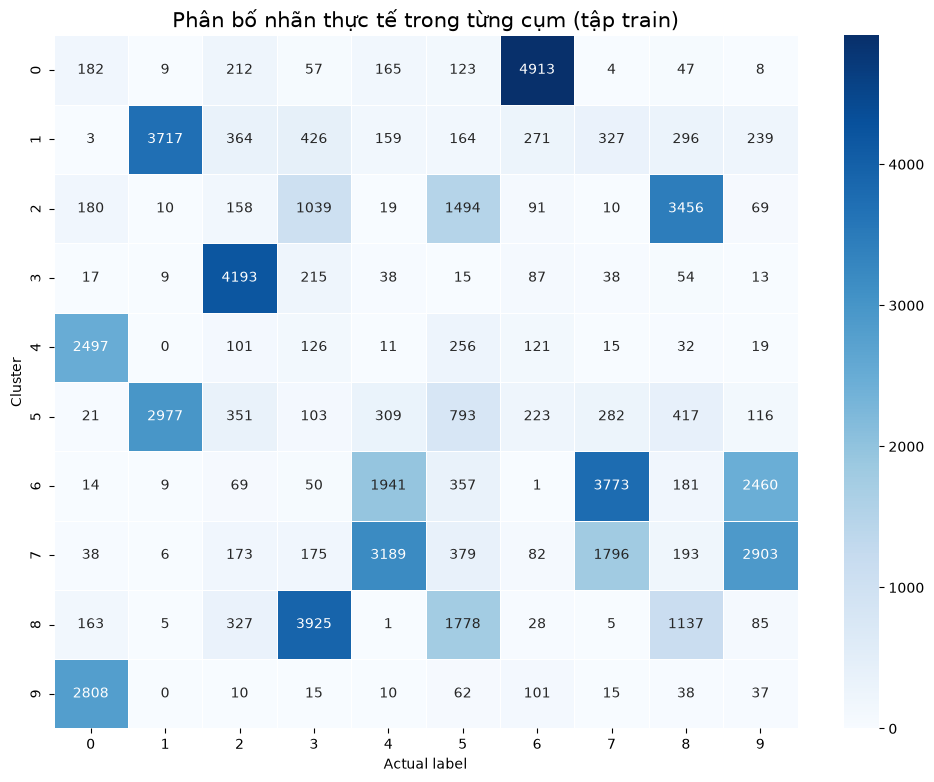

In [7]:
# Ma trận: hàng là cụm, cột là nhãn thực tế (chữ số)
contingency = pd.crosstab(pd.Series(train_clusters, name='Cluster'),
                          pd.Series(train_labels, name='Actual label'))

plt.figure(figsize=(12, 9))
sns.heatmap(contingency, annot=True, fmt='d', cmap='Blues', linewidths=.5)
plt.title('Phân bố nhãn thực tế trong từng cụm (tập train)', size=15)
plt.show()

Đặng Phan Duy - 6451071010

### 4.2. Gán nhãn cho từng cụm

k-Means chỉ đánh số cụm (0 - 9) mà không biết cụm đó là chữ số nào. Mỗi cụm được gán nhãn là chữ số xuất hiện nhiều nhất trong cụm (majority vote) trên tập train.

In [8]:
cluster_to_label = {}
for cluster in range(kmeans.n_clusters):
    counts = np.bincount(train_labels[train_clusters == cluster], minlength=10)
    cluster_to_label[cluster] = np.argmax(counts)
    print("Cluster {0} -> chữ số {1} (chiếm {2:.2%} số mẫu của cụm)".format(
        cluster, cluster_to_label[cluster], counts.max() / counts.sum()))

missing = sorted(set(range(10)) - set(cluster_to_label.values()))
print("\nCác chữ số không được cụm nào đại diện:", missing)

Cluster 0 -> chữ số 6 (chiếm 85.89% số mẫu của cụm)
Cluster 1 -> chữ số 1 (chiếm 62.30% số mẫu của cụm)
Cluster 2 -> chữ số 8 (chiếm 52.96% số mẫu của cụm)
Cluster 3 -> chữ số 2 (chiếm 89.61% số mẫu của cụm)
Cluster 4 -> chữ số 0 (chiếm 78.57% số mẫu của cụm)
Cluster 5 -> chữ số 1 (chiếm 53.24% số mẫu của cụm)
Cluster 6 -> chữ số 7 (chiếm 42.61% số mẫu của cụm)
Cluster 7 -> chữ số 4 (chiếm 35.70% số mẫu của cụm)
Cluster 8 -> chữ số 3 (chiếm 52.66% số mẫu của cụm)
Cluster 9 -> chữ số 0 (chiếm 90.70% số mẫu của cụm)

Các chữ số không được cụm nào đại diện: [5, 9]


Đặng Phan Duy - 6451071010

### 4.3. Đánh giá trên tập train

In [9]:
train_pred = np.array([cluster_to_label[c] for c in train_clusters])
print("Accuracy (train):", metrics.accuracy_score(train_labels, train_pred))

Accuracy (train): 0.5908


Đặng Phan Duy - 6451071010

### 4.4. Đánh giá trên tập test

In [10]:
# Đưa các ảnh test vào cụm gần nhất, sau đó chuyển cụm thành nhãn
test_clusters = kmeans.predict(X_test)
test_pred = np.array([cluster_to_label[c] for c in test_clusters])

kmeans_score = metrics.accuracy_score(test_labels, test_pred)
print("Accuracy (test):", kmeans_score)
print("Report:\n", metrics.classification_report(test_labels, test_pred, digits=4, zero_division=0))

Accuracy (test): 0.595
Report:
               precision    recall  f1-score   support

           0     0.8360    0.8898    0.8621       980
           1     0.6129    0.9947    0.7585      1135
           2     0.8849    0.6851    0.7723      1032
           3     0.5293    0.6891    0.5987      1010
           4     0.3606    0.5692    0.4415       982
           5     0.0000    0.0000    0.0000       892
           6     0.8558    0.8299    0.8426       958
           7     0.4223    0.5866    0.4910      1028
           8     0.5384    0.6047    0.5696       974
           9     0.0000    0.0000    0.0000      1009

    accuracy                         0.5950     10000
   macro avg     0.5040    0.5849    0.5336     10000
weighted avg     0.5095    0.5950    0.5408     10000



Đặng Phan Duy - 6451071010

In [11]:
kmeans_cm = metrics.confusion_matrix(test_labels, test_pred, labels=range(10))

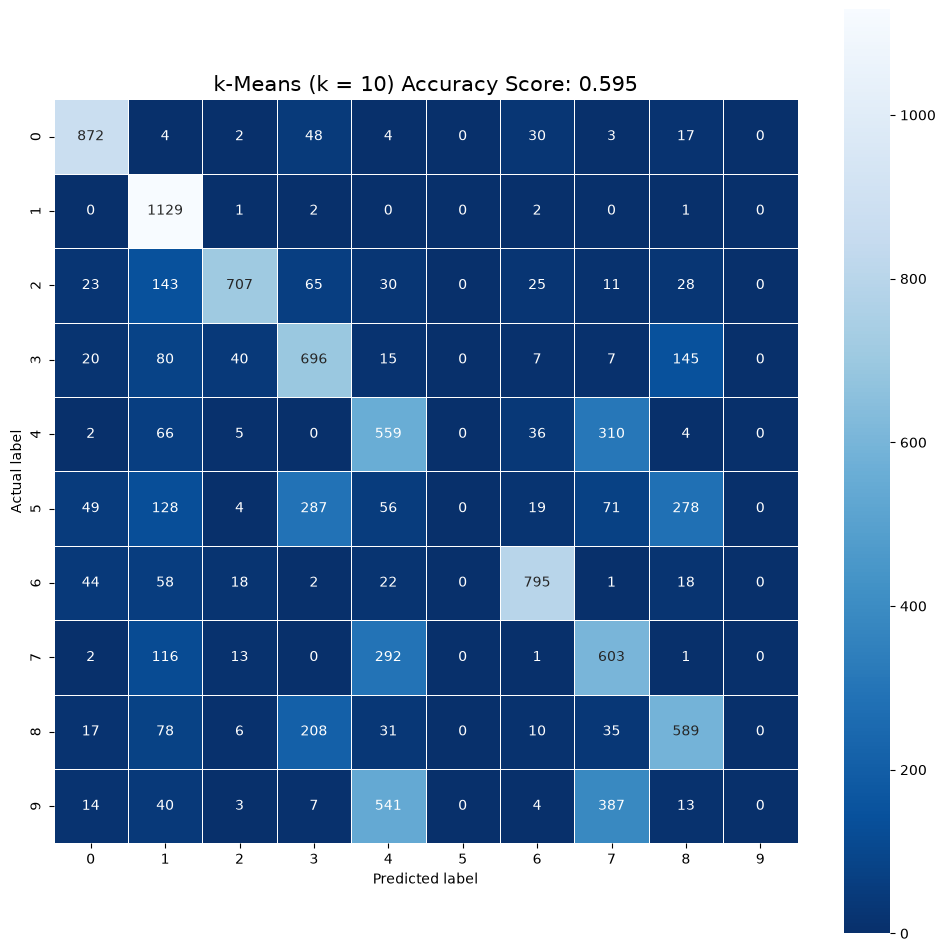

In [12]:
plt.figure(figsize=(12,12))
sns.heatmap(kmeans_cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'k-Means (k = 10) Accuracy Score: {0}'.format(kmeans_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

### 4.5. Các độ đo đánh giá gom cụm

- **Homogeneity**: mỗi cụm chỉ chứa các mẫu của một lớp.
- **Completeness**: tất cả các mẫu của một lớp nằm trong cùng một cụm.
- **V-measure**: trung bình điều hòa của Homogeneity và Completeness.
- **Adjusted Rand Index (ARI)**, **Normalized Mutual Information (NMI)**: mức độ trùng khớp giữa cụm và nhãn thực tế (1 là trùng khớp hoàn toàn, ~0 là ngẫu nhiên).
- **Silhouette coefficient**: độ gắn kết và tách biệt của các cụm, không cần nhãn (tính trên 10000 mẫu train ngẫu nhiên để giảm thời gian chạy).

In [13]:
rng = np.random.RandomState(42)
sample = rng.choice(len(X_train), 10000, replace=False)

cluster_metrics = pd.DataFrame({
    'Metric': ['Homogeneity', 'Completeness', 'V-measure', 'Adjusted Rand Index', 'Normalized Mutual Information', 'Silhouette coefficient'],
    'Value': [metrics.homogeneity_score(test_labels, test_clusters),
              metrics.completeness_score(test_labels, test_clusters),
              metrics.v_measure_score(test_labels, test_clusters),
              metrics.adjusted_rand_score(test_labels, test_clusters),
              metrics.normalized_mutual_info_score(test_labels, test_clusters),
              metrics.silhouette_score(X_train[sample], train_clusters[sample], metric='euclidean')]
})
cluster_metrics

,Metric,Value
0,Homogeneity,0.493250
1,Completeness,0.505511
2,V-measure,0.499305
3,Adjusted Rand Index,0.367114
4,Normalized Mutual Information,0.499305
5,Silhouette coefficient,0.057876


Đặng Phan Duy - 6451071010

### 4.6. Kết quả phân cụm của 05 ảnh đầu tiên và 05 ảnh bị gán sai đầu tiên trong tập test

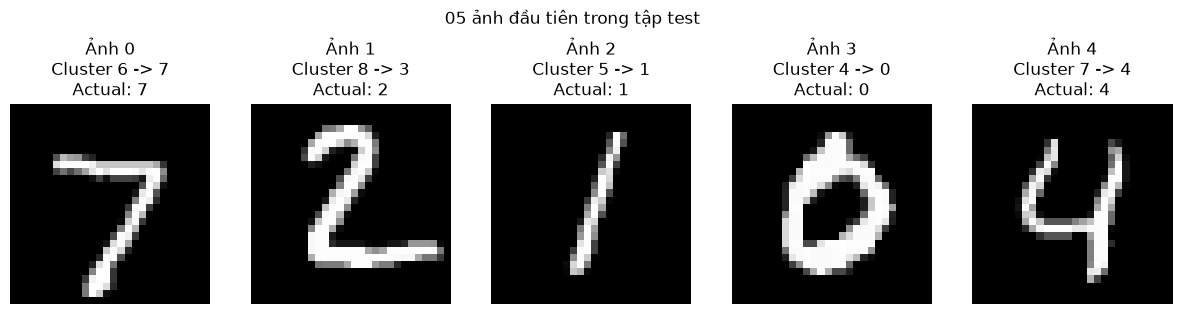

Số ảnh bị gán sai: 4050 / 10000


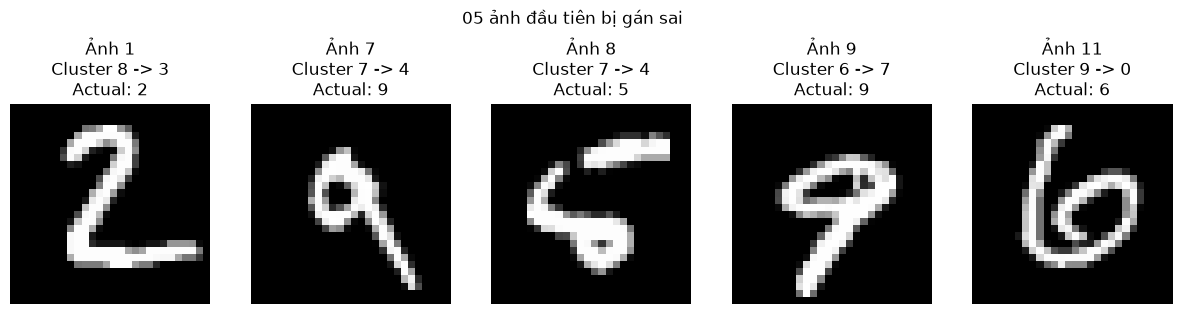

In [14]:
def show_images(indexes, title):
    plt.figure(figsize=(15, 4))
    for i, image_index in enumerate(indexes):
        plt.subplot(1, len(indexes), i + 1)
        plt.imshow(test_images[image_index], cmap='gray')
        plt.title('Ảnh {0}\nCluster {1} -> {2}\nActual: {3}'.format(
            image_index, test_clusters[image_index], test_pred[image_index], test_labels[image_index]))
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

show_images(range(5), '05 ảnh đầu tiên trong tập test')

wrong_index = np.where(test_pred != test_labels)[0]
print("Số ảnh bị gán sai:", len(wrong_index), "/", len(test_labels))
show_images(wrong_index[:5], '05 ảnh đầu tiên bị gán sai')

Đặng Phan Duy - 6451071010

## 5. Thử với số cụm k lớn hơn

Mỗi chữ số có nhiều kiểu viết khác nhau (ví dụ số 7 có gạch ngang hoặc không), nên một chữ số có thể cần nhiều cụm để biểu diễn. Thử tăng số cụm và gán nhãn bằng majority vote như trên.

In [15]:
k_results = []
for k in [10, 20, 30, 50]:
    km = KMeans(n_clusters=k, n_init=3, random_state=42).fit(X_train)
    mapping = np.array([np.argmax(np.bincount(train_labels[km.labels_ == c], minlength=10)) for c in range(k)])
    pred = mapping[km.predict(X_test)]
    k_results.append([k, km.inertia_, metrics.accuracy_score(test_labels, pred),
                      metrics.f1_score(test_labels, pred, average='macro')])

k_results = pd.DataFrame(k_results, columns=['k', 'Inertia', 'Accuracy (test)', 'F1 macro (test)'])
k_results

,k,Inertia,Accuracy (test),F1 macro (test)
0,10,2.352953e+06,0.5896,0.526487
1,20,2.109786e+06,0.7231,0.721733
2,30,1.985734e+06,0.7690,0.761722
3,50,1.842595e+06,0.8218,0.818168


Đặng Phan Duy - 6451071010

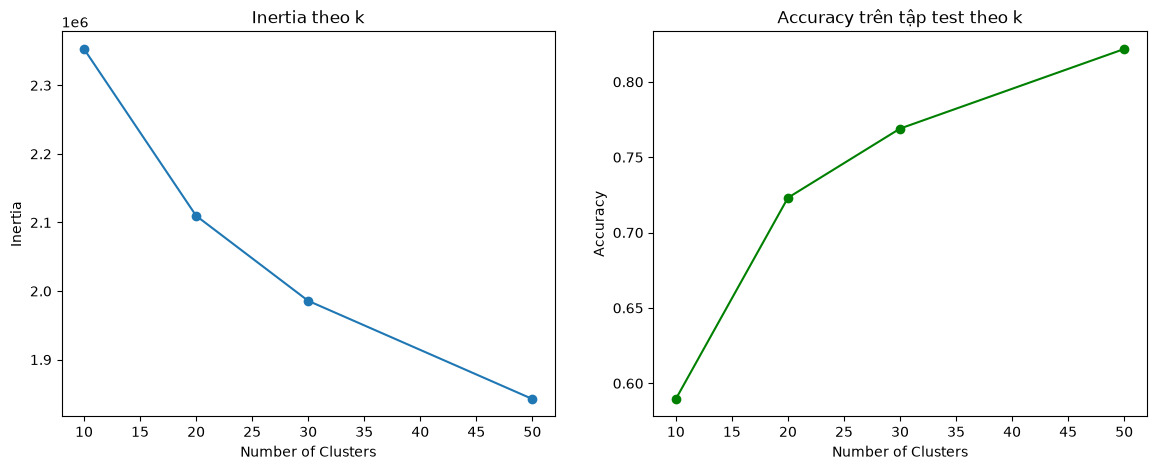

In [16]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(k_results['k'], k_results['Inertia'], 'o-')
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Inertia theo k')

plt.subplot(1, 2, 2)
plt.plot(k_results['k'], k_results['Accuracy (test)'], 'o-', color='green')
plt.xlabel('Number of Clusters'), plt.ylabel('Accuracy')
plt.title('Accuracy trên tập test theo k')
plt.show()

Đặng Phan Duy - 6451071010

## 6. Nhận xét

Nhận xét:

- Với k = 10, k-Means gom cụm MNIST chỉ đạt Accuracy ≈ 0.595 trên tập test (≈ 0.591 trên tập train), thấp hơn nhiều so với Neural Network ở bài 2 (≈ 0.9745). Lý do là k-Means là thuật toán học không giám sát: không dùng nhãn khi huấn luyện, chỉ gom các ảnh có giá trị pixel gần nhau (khoảng cách Euclide) chứ không học được đặc trưng hình dạng của từng chữ số.
- 10 cụm không tương ứng 1 - 1 với 10 chữ số: chữ số 0 và chữ số 1 mỗi số chiếm 2 cụm (các kiểu viết khác nhau, ví dụ số 1 viết thẳng và viết nghiêng), trong khi chữ số 5 và 9 không có cụm riêng. Chữ số 9 bị trộn với 4 và 7 (các cụm 6 và 7), chữ số 5 bị trộn với 3 và 8 (các cụm 2 và 8) do hình dạng các chữ số này gần giống nhau. Vì vậy Recall, Precision của lớp 5 và 9 bằng 0, còn Precision của các lớp 4, 7, 3, 8 thấp.
- Các chữ số có hình dạng đặc trưng như 0, 2, 6 được gom cụm tốt (F1-score ≈ 0.77 - 0.86); tâm cụm hiển thị dưới dạng ảnh cũng nhận ra rõ các chữ số này.
- Các độ đo gom cụm đều ở mức trung bình: Homogeneity, Completeness, V-measure, NMI ≈ 0.5; ARI ≈ 0.37. Hệ số Silhouette rất thấp (≈ 0.06) cho thấy trong không gian 784 chiều, các cụm nằm sát nhau và chồng lấn nhiều, không tách biệt rõ ràng.
- Khi tăng số cụm k (20, 30, 50) thì inertia giảm và Accuracy tăng dần (≈ 0.72 → 0.77 → 0.82 với k = 50), vì mỗi chữ số được biểu diễn bởi nhiều cụm tương ứng với các kiểu viết khác nhau. Tuy nhiên đây là gán nhãn dựa trên majority vote có dùng nhãn của tập train, nên không còn hoàn toàn là gom cụm không giám sát.
- Kết luận: k-Means có thể phát hiện được một phần cấu trúc của dữ liệu MNIST nhưng không thay thế được các mô hình phân lớp có giám sát. Để cải thiện kết quả gom cụm có thể giảm chiều dữ liệu (PCA, t-SNE, autoencoder) trước khi chạy k-Means.